
# Neural Networks 101

## Fundamentals

For this example we are going to use the classic example of a number classifier, which takes in 784 inputs from a 28x28 pixel space and outputs an answer from 0-9. We are going to start by defining the mathematical terms.

![Multilayer perceptron for digit classification](../images/mlp_architecture.png)

We will be using this example from the 3Blue1Brown channel. https://www.youtube.com/watch?v=aircAruvnKk&list=PLZHQObOWTQDN52m7Y21ePrTbvXkPaWVSg

## Neurons and layers

Each neuron has an activation value $a$ from 0 to 1.
Layer 1 is our 784 input neurons, layers 2 and 3 are our hidden middle layers with 16 neurons each (an arbitrary choice for this example), and our 4th answer layer has 10 answer neurons.

The highest value of $a$ in layer 4 is the answer given by the neural network, given the 784 input values.

## Weights

The weights ($w$) are the multipliers that determine how much the magnitude of $a_1$ affects the value of the neuron in the following layer.

And so the value of a neuron in layer 2 is determined by the sum of all activations multiplied by their individual weights. As this can result in a value outside of 0 to 1, we wrap the function in a sigmoid function, so we keep all $a$ values between 0 and 1.


## The activation function

For a single neuron in the next layer:

$$
a^{(1)} = \sigma\left(w_1 a_1 + w_2 a_2 + w_3 a_3 + \cdots + w_n a_n\right) = \sigma\left(\sum_{i=1}^{n} w_i a_i\right)
$$

where the sigmoid function is:

$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$

 The final term in this fundamental function is the bias ($b$). It is added to the weighted sum before it is passed through the sigmoid function, and shifts the result up or down. This changes how large the weighted sum needs to be before the neuron activates, so each neuron has its own threshold. Like the weights, the bias is not chosen by hand. It is learned during training.

 Full equation:

  $$a^{(1)} = \sigma\left(\sum_{i=1}^{n} w_i a_i + b\right)$$



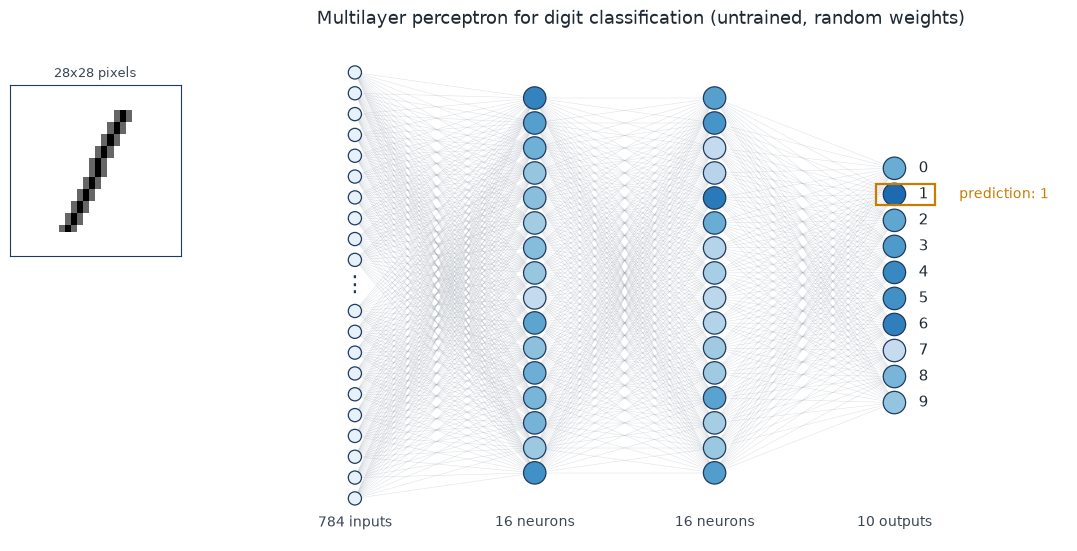

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from nn101.data import make_digit_one
from nn101.plotting import plot_mlp


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def forward(x, layer_sizes, seed=0):
    """Forward pass through a randomly initialised sigmoid network. Returns activations per layer."""
    rng = np.random.default_rng(seed)
    acts = [x]
    a = x
    for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
        W = rng.normal(0, 1 / np.sqrt(n_in), size=(n_out, n_in))
        b = rng.normal(0, 0.5, size=n_out)
        a = sigmoid(W @ a + b)
        acts.append(a)
    return acts


# Draw the network with a synthetic digit fed through random, untrained weights
img = make_digit_one()
acts = forward(img.flatten(), (784, 16, 16, 10), seed=0)
fig, ax = plot_mlp((784, 16, 16, 10), activations=acts, input_image=img,
                   title="Multilayer perceptron for digit classification (untrained, random weights)")
fig.savefig("../images/mlp_architecture.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
